In [1]:
import sys

sys.argv = [""]  # to avoid issues with Jupyter and argparse

In [2]:
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import arviz as az
import xarray
from scipy.stats import qmc
from ipywidgets import interact, IntSlider
import matplotlib.pyplot as plt
from pathlib import Path
import json
import ICIW_Plots
import numpy as np

plt.style.use("ICIWstyle")
plt.rcParams["figure.dpi"] = 600
plt.rcParams["font.size"] = 7

In [3]:
%config InlineBackend.print_figure_kwargs = {'bbox_inches':None}

In [4]:
from HSA_Cam_D_007 import (
    calculate_partial_pressures,
    predict_funs,
    JSD_marginal,
    JSD_between_predictions,
    calculate_disagreement,
    LHSDOE,
    generate_synthetic_data,
    find_opt_candidate,
)
from HSA_Mo_D_001_numpyro import validate_against_holdout as validate_Mo1
from HSA_Mo_D_002_numpyro import validate_against_holdout as validate_Mo2
from HSA_Mo_D_003_numpyro import validate_against_holdout as validate_Mo3
from HSA_Mo_D_004_numpyro import validate_against_holdout as validate_Mo4

validate_funs = {
    "Mo1": validate_Mo1,
    "Mo2": validate_Mo2,
    "Mo3": validate_Mo3,
    "Mo4": validate_Mo4,
}

In [5]:
exp_id = "quality-tribute"
data_path = Path(f"data/{exp_id}/")
multiseed_summary_file = data_path/"multi_seed_summary.json"

with open(multiseed_summary_file, "r") as f:
    multiseed_summary = json.load(f)

seeds = multiseed_summary["seeds_used"]
display(seeds)

[43, 44, 45, 46, 47]

In [6]:
ov=[]

for seed in seeds:
    seed_path = data_path/f"seed{seed:03d}"
    trace_files = {
        "Mo1": sorted(seed_path.glob("Mo1_trace_*.nc")),
        "Mo2": sorted(seed_path.glob("Mo2_trace_*.nc")),
        "Mo3": sorted(seed_path.glob("Mo3_trace_*.nc")),
        "Mo4": sorted(seed_path.glob("Mo4_trace_*.nc")),
    }
    sum_file = seed_path/"experiment_summary.json"
    with open(sum_file, "r") as f:
        summary= json.load(f)
    display(len(summary["trials"]))
    proposals = jnp.array(summary["trials"][-1]["observed"]["x"])
    r_obs = jnp.array(summary["trials"][-1]["observed"]["y"])
    idatas = {
        "Mo1": [],
        "Mo2": [],
        "Mo3": [],
        "Mo4": [],
    }

    errored_files = []

    for Mo, Mo_trace_files in trace_files.items():
        for i, Mo_trace_file in enumerate(Mo_trace_files):
            print(f"Loading {Mo_trace_file}")
            try:
                Mo_idata = az.from_netcdf(Mo_trace_file)
                idatas[Mo].append(Mo_idata)
            except Exception as e:
                idatas[Mo].append(None)
                errored_files.append((Mo, i, Mo_trace_file))
                print(f"Could not load {Mo_trace_file}: {e}")
                continue
    for model_idatas in idatas.values():
        for i, idata in enumerate(model_idatas):
            if i == 0:
                continue
            else:
                idata["prior"] =  model_idatas[i - 1].posterior

    ov.append(
        {   
            "seed": seed,
            "idatas": idatas,
            "proposals":proposals,
            "r_obs": r_obs
        }
    )

8

Loading data/quality-tribute/seed043/Mo1_trace_000.nc
Loading data/quality-tribute/seed043/Mo1_trace_001.nc
Loading data/quality-tribute/seed043/Mo1_trace_002.nc
Loading data/quality-tribute/seed043/Mo1_trace_003.nc
Loading data/quality-tribute/seed043/Mo1_trace_004.nc
Loading data/quality-tribute/seed043/Mo1_trace_005.nc
Loading data/quality-tribute/seed043/Mo1_trace_006.nc
Loading data/quality-tribute/seed043/Mo1_trace_007.nc
Loading data/quality-tribute/seed043/Mo1_trace_008.nc
Loading data/quality-tribute/seed043/Mo2_trace_000.nc
Loading data/quality-tribute/seed043/Mo2_trace_001.nc
Loading data/quality-tribute/seed043/Mo2_trace_002.nc
Loading data/quality-tribute/seed043/Mo2_trace_003.nc
Loading data/quality-tribute/seed043/Mo2_trace_004.nc
Loading data/quality-tribute/seed043/Mo2_trace_005.nc
Loading data/quality-tribute/seed043/Mo2_trace_006.nc
Loading data/quality-tribute/seed043/Mo2_trace_007.nc
Loading data/quality-tribute/seed043/Mo2_trace_008.nc
Loading data/quality-tribute

8

Loading data/quality-tribute/seed044/Mo1_trace_000.nc
Loading data/quality-tribute/seed044/Mo1_trace_001.nc
Loading data/quality-tribute/seed044/Mo1_trace_002.nc
Loading data/quality-tribute/seed044/Mo1_trace_003.nc
Loading data/quality-tribute/seed044/Mo1_trace_004.nc
Loading data/quality-tribute/seed044/Mo1_trace_005.nc
Loading data/quality-tribute/seed044/Mo1_trace_006.nc
Loading data/quality-tribute/seed044/Mo1_trace_007.nc
Loading data/quality-tribute/seed044/Mo1_trace_008.nc
Loading data/quality-tribute/seed044/Mo2_trace_000.nc
Loading data/quality-tribute/seed044/Mo2_trace_001.nc
Loading data/quality-tribute/seed044/Mo2_trace_002.nc
Loading data/quality-tribute/seed044/Mo2_trace_003.nc
Loading data/quality-tribute/seed044/Mo2_trace_004.nc
Loading data/quality-tribute/seed044/Mo2_trace_005.nc
Loading data/quality-tribute/seed044/Mo2_trace_006.nc
Loading data/quality-tribute/seed044/Mo2_trace_007.nc
Loading data/quality-tribute/seed044/Mo2_trace_008.nc
Loading data/quality-tribute

8

Loading data/quality-tribute/seed045/Mo1_trace_000.nc
Loading data/quality-tribute/seed045/Mo1_trace_001.nc
Loading data/quality-tribute/seed045/Mo1_trace_002.nc
Loading data/quality-tribute/seed045/Mo1_trace_003.nc
Loading data/quality-tribute/seed045/Mo1_trace_004.nc
Loading data/quality-tribute/seed045/Mo1_trace_005.nc
Loading data/quality-tribute/seed045/Mo1_trace_006.nc
Loading data/quality-tribute/seed045/Mo1_trace_007.nc
Loading data/quality-tribute/seed045/Mo1_trace_008.nc
Loading data/quality-tribute/seed045/Mo2_trace_000.nc
Loading data/quality-tribute/seed045/Mo2_trace_001.nc
Loading data/quality-tribute/seed045/Mo2_trace_002.nc
Loading data/quality-tribute/seed045/Mo2_trace_003.nc
Loading data/quality-tribute/seed045/Mo2_trace_004.nc
Loading data/quality-tribute/seed045/Mo2_trace_005.nc
Loading data/quality-tribute/seed045/Mo2_trace_006.nc
Loading data/quality-tribute/seed045/Mo2_trace_007.nc
Loading data/quality-tribute/seed045/Mo2_trace_008.nc
Loading data/quality-tribute

8

Loading data/quality-tribute/seed046/Mo1_trace_000.nc
Loading data/quality-tribute/seed046/Mo1_trace_001.nc
Loading data/quality-tribute/seed046/Mo1_trace_002.nc
Loading data/quality-tribute/seed046/Mo1_trace_003.nc
Loading data/quality-tribute/seed046/Mo1_trace_004.nc
Loading data/quality-tribute/seed046/Mo1_trace_005.nc
Loading data/quality-tribute/seed046/Mo1_trace_006.nc
Loading data/quality-tribute/seed046/Mo1_trace_007.nc
Loading data/quality-tribute/seed046/Mo1_trace_008.nc
Loading data/quality-tribute/seed046/Mo2_trace_000.nc
Loading data/quality-tribute/seed046/Mo2_trace_001.nc
Loading data/quality-tribute/seed046/Mo2_trace_002.nc
Loading data/quality-tribute/seed046/Mo2_trace_003.nc
Loading data/quality-tribute/seed046/Mo2_trace_004.nc
Loading data/quality-tribute/seed046/Mo2_trace_005.nc
Loading data/quality-tribute/seed046/Mo2_trace_006.nc
Loading data/quality-tribute/seed046/Mo2_trace_007.nc
Loading data/quality-tribute/seed046/Mo2_trace_008.nc
Loading data/quality-tribute

8

Loading data/quality-tribute/seed047/Mo1_trace_000.nc
Loading data/quality-tribute/seed047/Mo1_trace_001.nc
Loading data/quality-tribute/seed047/Mo1_trace_002.nc
Loading data/quality-tribute/seed047/Mo1_trace_003.nc
Loading data/quality-tribute/seed047/Mo1_trace_004.nc
Loading data/quality-tribute/seed047/Mo1_trace_005.nc
Loading data/quality-tribute/seed047/Mo1_trace_006.nc
Loading data/quality-tribute/seed047/Mo1_trace_007.nc
Loading data/quality-tribute/seed047/Mo1_trace_008.nc
Loading data/quality-tribute/seed047/Mo2_trace_000.nc
Loading data/quality-tribute/seed047/Mo2_trace_001.nc
Loading data/quality-tribute/seed047/Mo2_trace_002.nc
Loading data/quality-tribute/seed047/Mo2_trace_003.nc
Loading data/quality-tribute/seed047/Mo2_trace_004.nc
Loading data/quality-tribute/seed047/Mo2_trace_005.nc
Loading data/quality-tribute/seed047/Mo2_trace_006.nc
Loading data/quality-tribute/seed047/Mo2_trace_007.nc
Loading data/quality-tribute/seed047/Mo2_trace_008.nc
Loading data/quality-tribute

In [7]:
ov[0]["seed"]

43

In [8]:
@interact(
    i=IntSlider(
        min=0,
        max=8,
        step=1,
        value=0,
        description="Experiment Index",
    ),
    j=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    ),
    s = IntSlider(
        min=0,
        max=len(ov) - 1,
        step=1,
        value=0,
        description="Seed Index",
    ),
)
def interactive(i, j, s):
    fig = ICIW_Plots.figure(layout="single_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=5.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$t$ / h",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
        left_h=1.5 * ICIW_Plots.cm2inch,
        # yscale="log",
        # ylim=(1e-6, 1e-5),
        # xlim=(450, 600),
        xticks=[0, 2, 4, 6, 8, 10, 12],
    )
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

    T_prop = ov[s]["proposals"][j : j + 1, 0:1]
    p_prop = ov[s]["proposals"][j : j + 1, 1:2]
    c2h_prop = ov[s]["proposals"][j : j + 1, 2:3]
    c2m_prop = ov[s]["proposals"][j : j + 1, 3:4]
    c2w_prop = ov[s]["proposals"][j : j + 1, 4:5]
    c2i_prop = ov[s]["proposals"][j : j + 1, 5:6]

    pi_prop = calculate_partial_pressures(
        p_total=p_prop,
        c2h_ratio=c2h_prop,
        c2m_ratio=c2m_prop,
        c2w_ratio=c2w_prop,
        c2i_ratio=c2i_prop,
    )

    r_pred1 = predict_funs["Mo1"](
        ov[s]["idatas"]["Mo1"][i],
        T_prop,
        pi_prop,
        key="posterior",
    )
    r_pred2 = predict_funs["Mo2"](
        ov[s]["idatas"]["Mo2"][i],
        T_prop,
        pi_prop,
        key="posterior",
    )
    r_pred3 = predict_funs["Mo3"](
        ov[s]["idatas"]["Mo3"][i],
        T_prop,
        pi_prop,
        key="posterior",
    )
    r_pred4 = predict_funs["Mo4"](
        ov[s]["idatas"]["Mo4"][i],
        T_prop,
        pi_prop,
        key="posterior",
    )

    display(proposals[j])
    display(r_pred1.shape)

    t = jnp.linspace(
        0, 12, 10
    )  # Assuming time points are the same (10 in 12 h) for all models

    ax.plot(t, ov[s]["r_obs"][:, j, 0, 0], "k^", label="Obs.", markerfacecolor="None")

    ax.plot(t, r_pred1.mean(axis=3)[:, 0, 0], label="Mo1")
    ax.fill_between(
        t,
        az.hdi(np.array(r_pred1[:, 0, 0, :]), prob=0.95)[:, 0],
        az.hdi(np.array(r_pred1[:, 0, 0, :]), prob=0.95)[:, 1],
        color="C0",
        alpha=0.2,
        # label="90% credible interval",
    )
    ax.plot(t, r_pred2.mean(axis=3)[:, 0, 0], label="Mo2")
    ax.fill_between(
        t,
        az.hdi(np.array(r_pred2[:, 0, 0, :]), prob=0.95)[:, 0],
        az.hdi(np.array(r_pred2[:, 0, 0, :]), prob=0.95)[:, 1],
        color="C1",
        alpha=0.2,
        # label="90% credible interval",
    )
    ax.plot(t, r_pred3.mean(axis=3)[:, 0, 0], label="Mo3")
    ax.fill_between(
        t,
        az.hdi(np.array(r_pred3[:, 0, 0, :]), prob=0.95)[:, 0],
        az.hdi(np.array(r_pred3[:, 0, 0, :]), prob=0.95)[:, 1],
        color="C2",
        alpha=0.2,
        # label="90% credible interval",
    )
    ax.plot(t, r_pred4.mean(axis=3)[:, 0, 0], label="Mo4")
    ax.fill_between(
        t,
        az.hdi(np.array(r_pred4[:, 0, 0, :]), prob=0.95)[:, 0],
        az.hdi(np.array(r_pred4[:, 0, 0, :]), prob=0.95)[:, 1],
        color="C3",
        alpha=0.2,
        # label="90% credible interval",
    )
    # ax.legend(fancybox=False)

interactive(children=(IntSlider(value=0, description='Experiment Index', max=8), IntSlider(value=0, descriptio…

Array([597.49585  ,   4.0711203,   3.2041705, 318.73746  , 604.32587  ,
         0.6205559], dtype=float32)

(10, 1, 1, 25)

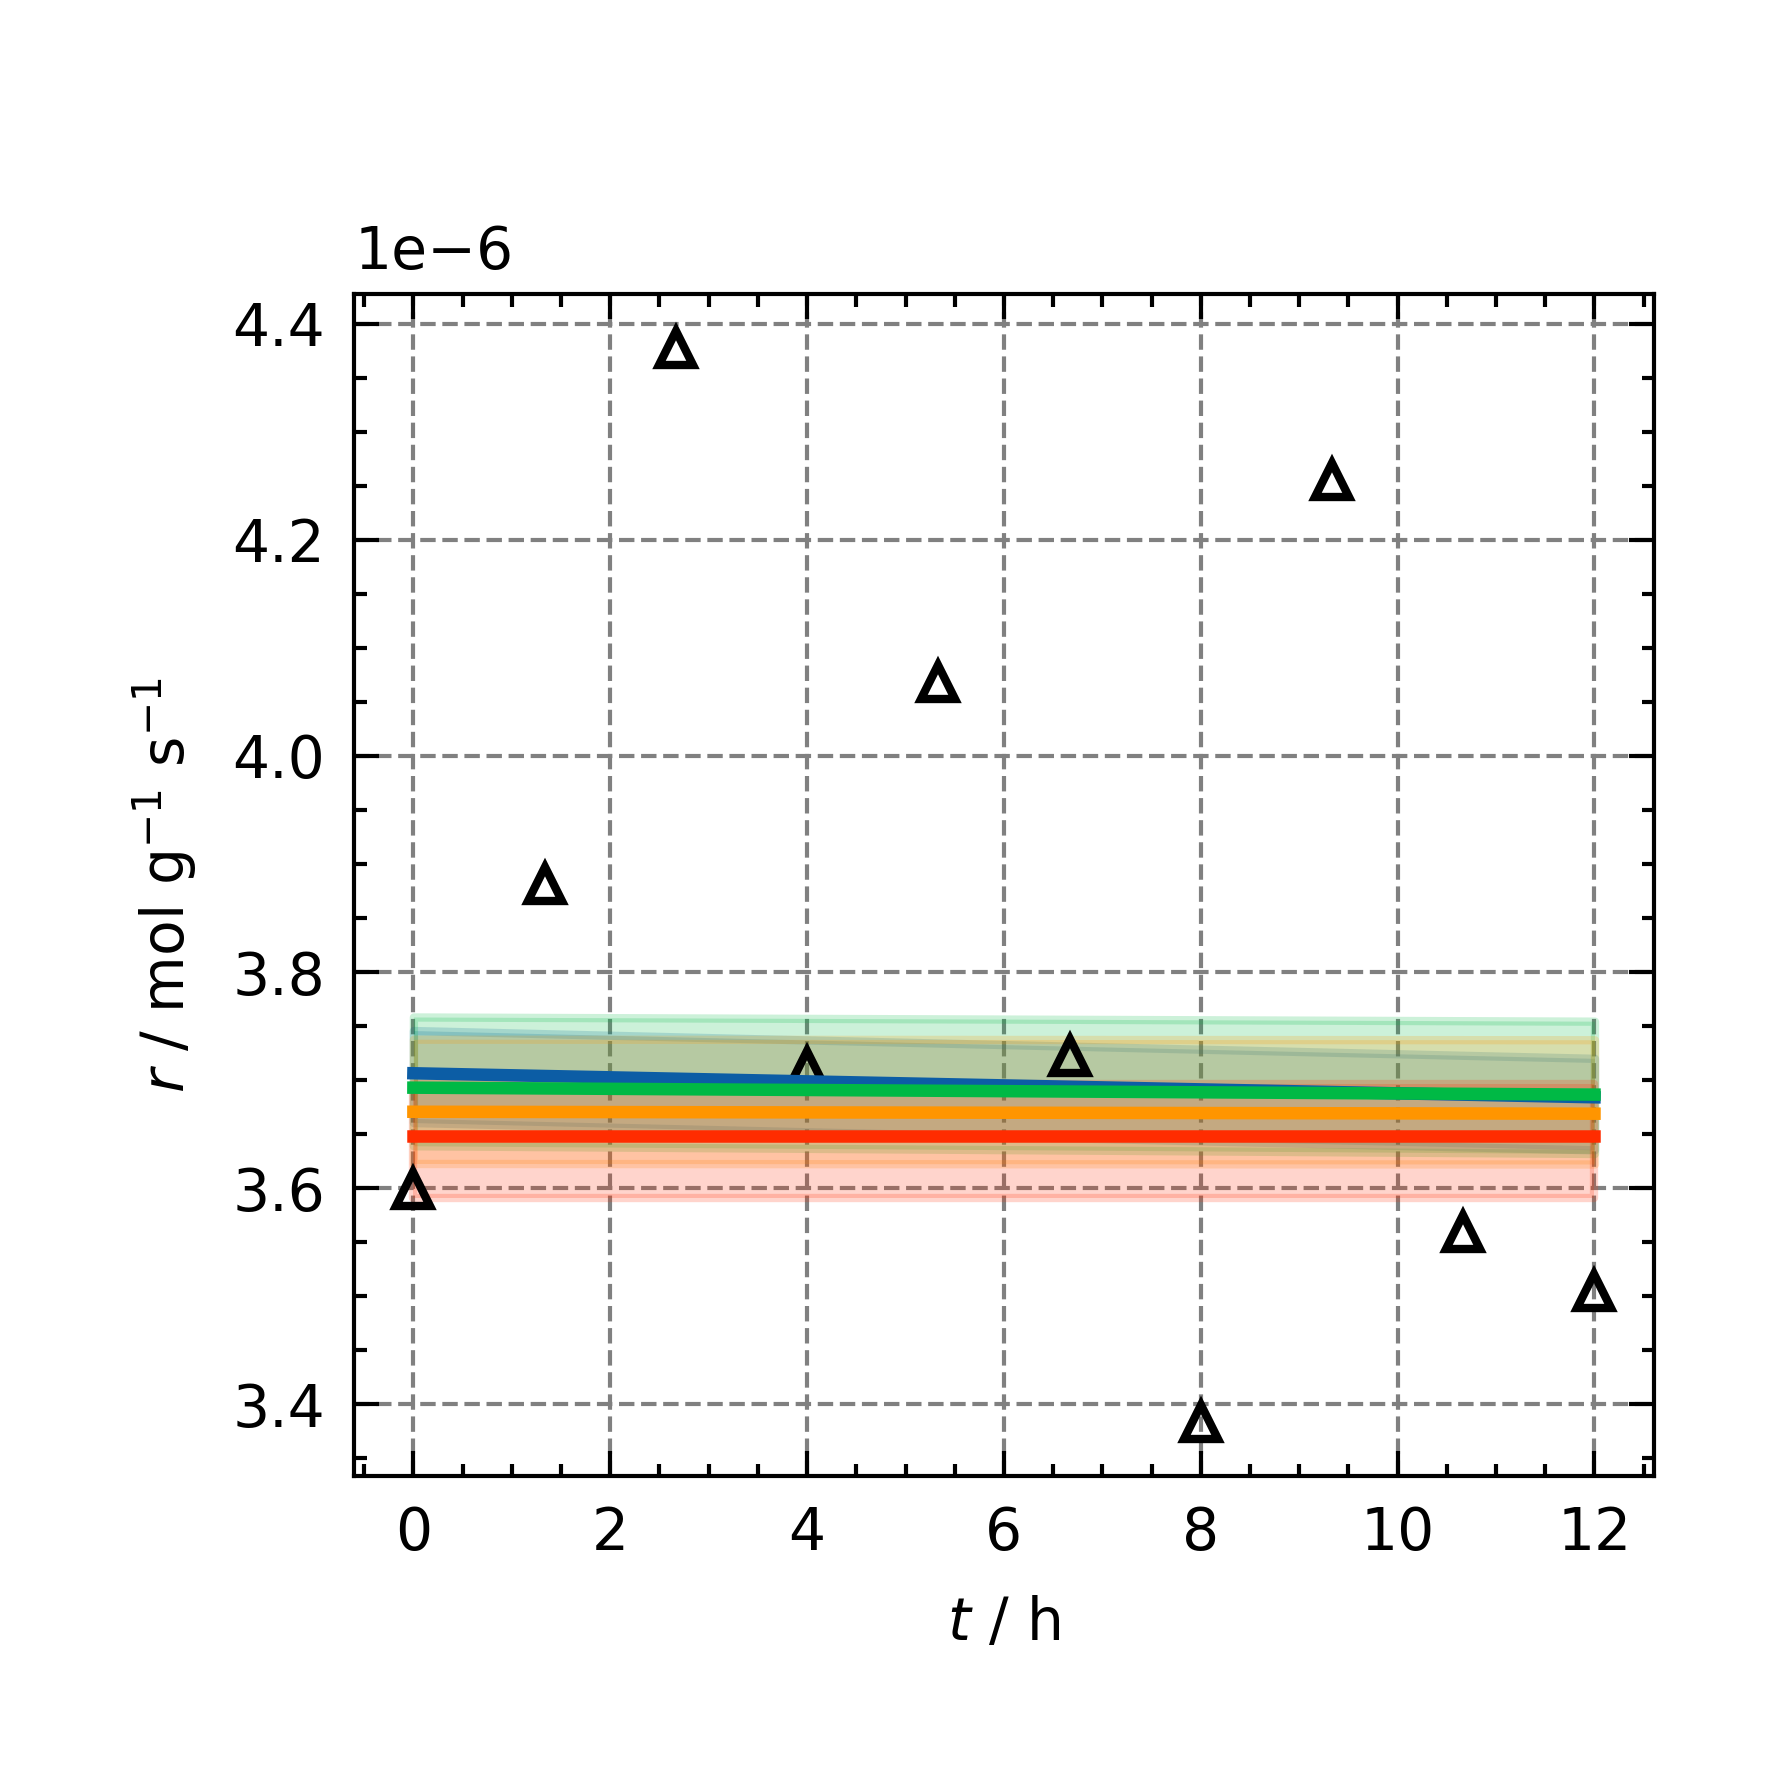

In [9]:
interactive(0, 1,2)

Array([6.e+02, 3.e+00, 2.e-01, 5.e-01, 5.e-01, 5.e-02], dtype=float32)

(10, 1, 1, 25)

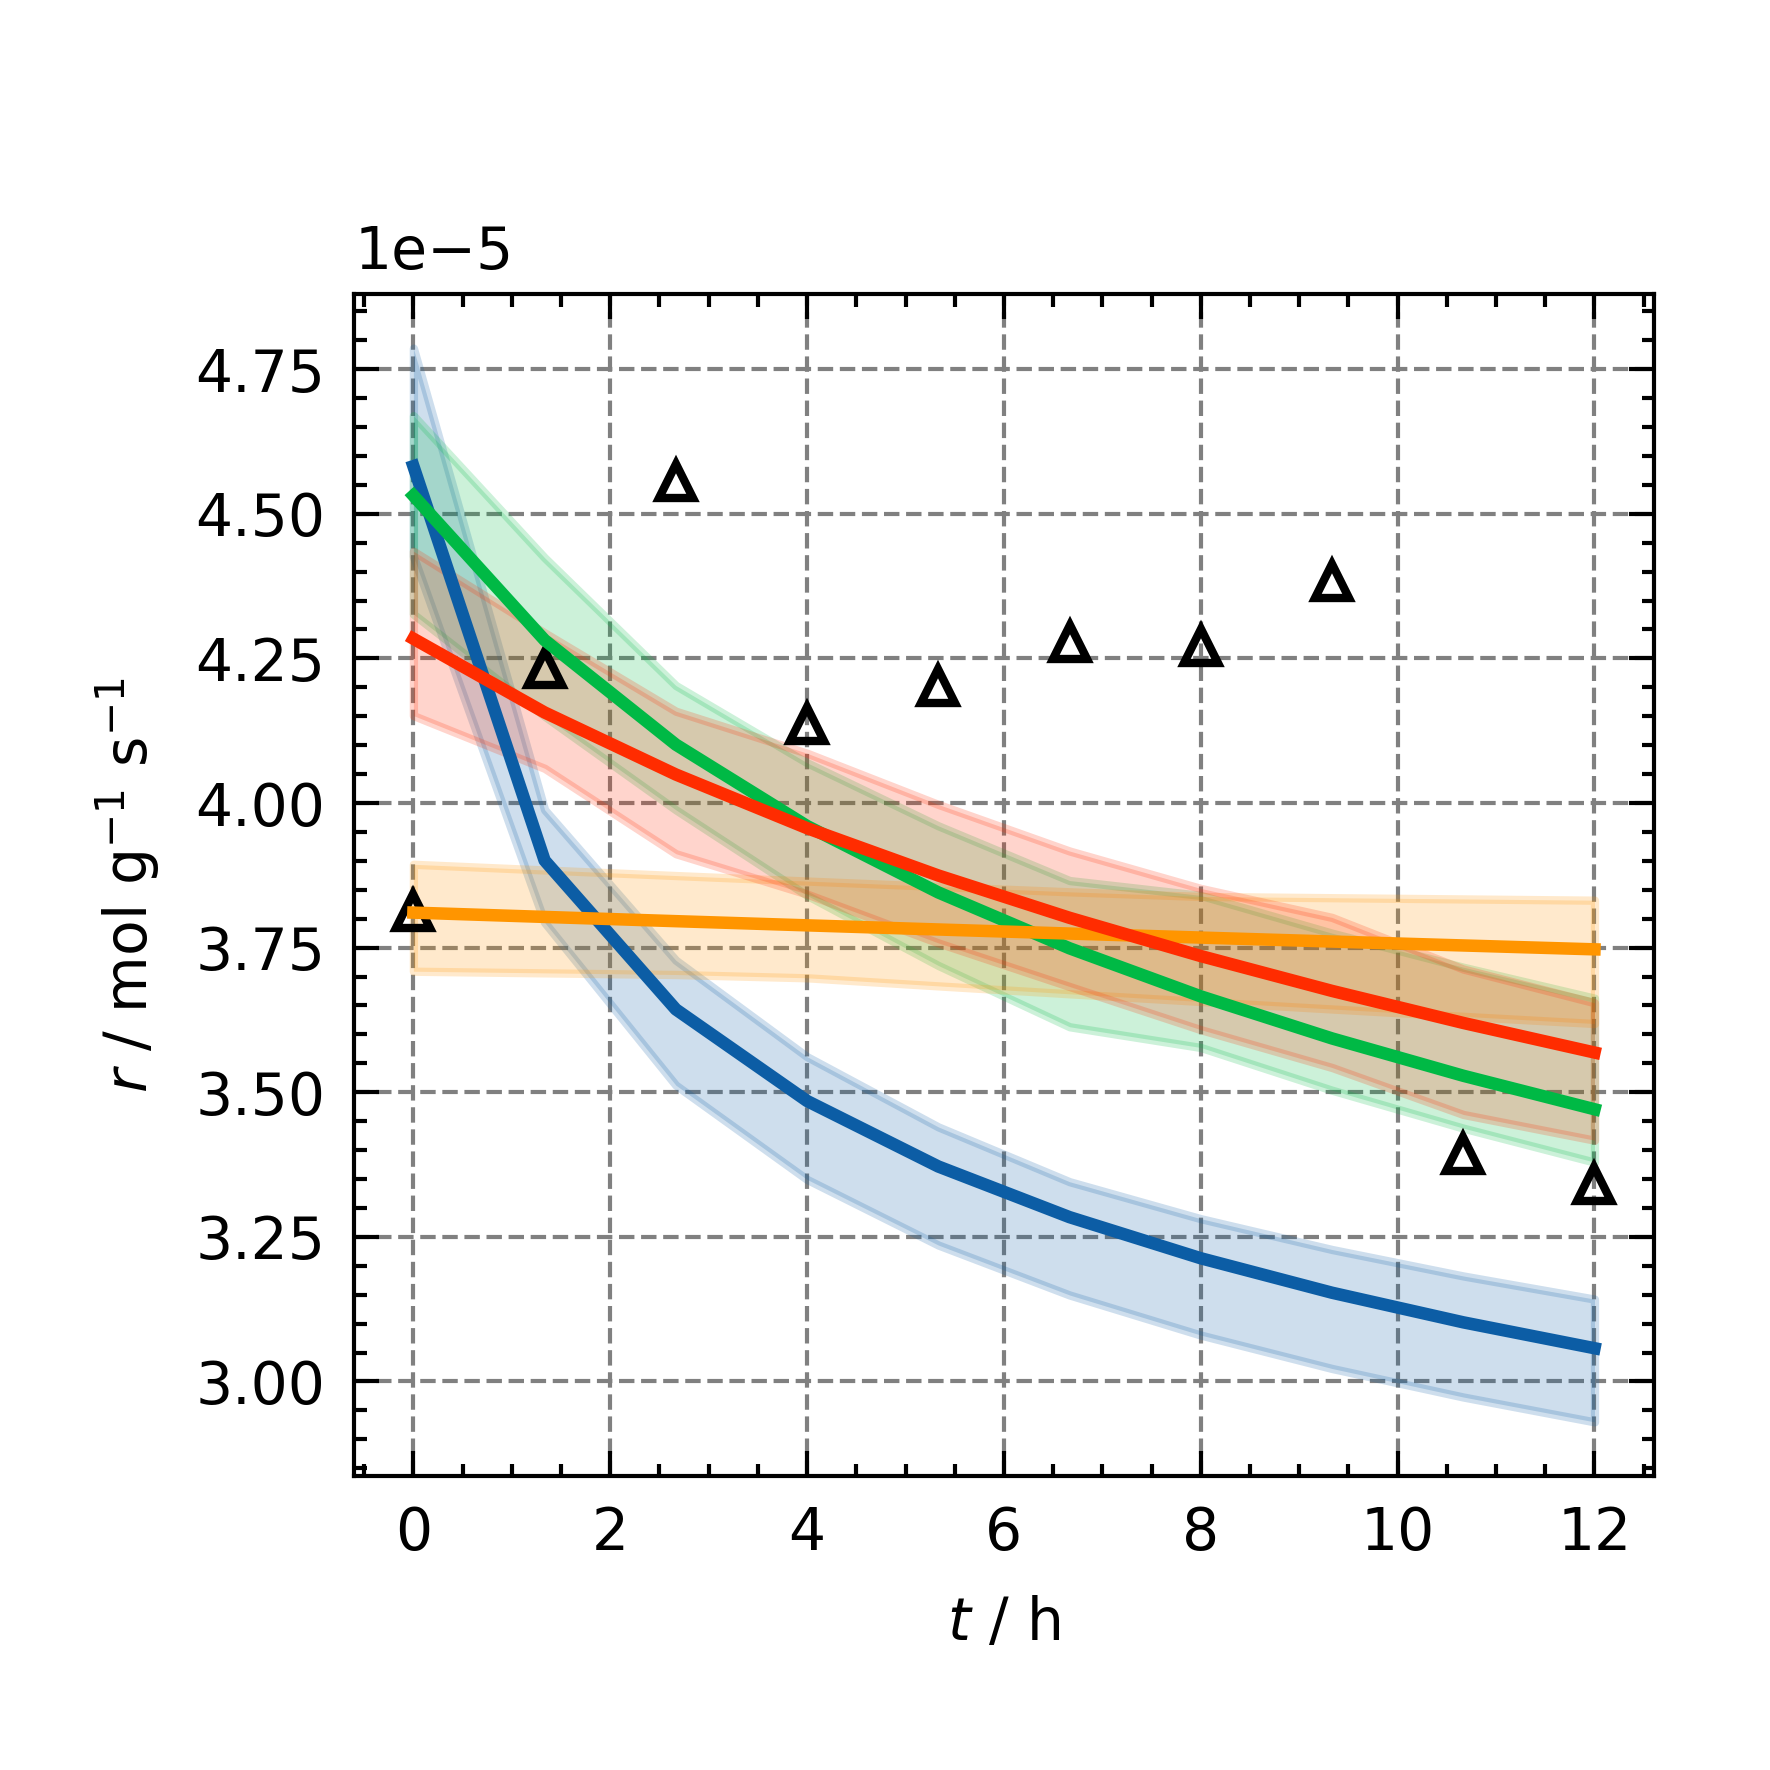

In [10]:
interactive(3, 12,2)

## RMSE

In [11]:
test_data = xarray.open_dataset(Path("data/test_HSA_Da_D_004.nc"))
display(test_data)

<xarray.Dataset> Size: 160kB
Dimensions:    (sample: 1000, parameter: 6, species: 5, time: 10, component: 1,
                draws: 1)
Coordinates:
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
  * time       (time) int64 80B 0 1 2 3 4 5 6 7 8 9
  * component  (component) <U1 4B 'a'
  * draws      (draws) int64 8B 0
Data variables:
    samples    (sample, parameter) float64 48kB ...
    T          (sample) float32 4kB ...
    p          (sample, species) float32 20kB ...
    latent_r   (time, sample, component, draws) float32 40kB ...
    obs_r      (time, sample, component, draws) float32 40kB ...
Attributes:
    noise:    homoscedastic
    sigma:    1e-05

In [12]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[
        var_name
    ].values  # shape (chain=1, draw=1, obs, times=10, 1)
    pred = postdata.posterior_predictive[
        var_name
    ].values  # shape (chain=1, draw, obs, times=10, n_samples)
    res = true - pred
    rmse_vals = jnp.sqrt(jnp.mean(res**2, axis=(2, 3, 4))).squeeze()
    rmse_da = xarray.DataArray(
        data=rmse_vals,
        dims=["draw"],
    )
    return rmse_da

In [13]:
for ov_dict in ov:
    postdatas={
        "Mo1": [],
        "Mo2": [],
        "Mo3": [],
        "Mo4": [],
    }
    RMSEs = {
        "Mo1": [],
        "Mo2": [],
        "Mo3": [],
        "Mo4": [],
    }
    for model_name, model_idatas in idatas.items():
        print(f"Calculating RMSE for {model_name}...")
        for i, idata in enumerate(model_idatas):
            print(f"Validating {model_name} for seed {ov_dict['seed']} and trial {i}...")
            postdata = validate_funs[model_name](idata, test_data, num_samples=985)
            postdatas[model_name].append(postdata)
            rmse_val = bRMSE(postdata, "r_lat")
            display(rmse_val.mean().item())
            RMSEs[model_name].append(rmse_val)
        RMSEs[model_name] = jnp.array(RMSEs[model_name])
    ov_dict["postdatas"] = postdatas
    ov_dict["RMSEs"] = RMSEs


Calculating RMSE for Mo1...
Validating Mo1 for seed 43 and trial 0...
(1000, 1) (1000, 5) None


4.1480257095827255e-06

Validating Mo1 for seed 43 and trial 1...
(1000, 1) (1000, 5) None


6.214007498783758e-06

Validating Mo1 for seed 43 and trial 2...
(1000, 1) (1000, 5) None


...

1.2138735883127083e-06

Validating Mo4 for seed 47 and trial 7...
(1000, 1) (1000, 5) None


1.3417750324151712e-06

Validating Mo4 for seed 47 and trial 8...
(1000, 1) (1000, 5) None


2.024309424086823e-06

In [14]:
display(ov[0]["RMSEs"]["Mo1"][1,456])
display(ov[2]["RMSEs"]["Mo1"][1,456])
display(ov[2]["RMSEs"]["Mo2"][1,456])

Array(6.182009e-06, dtype=float32)

Array(6.4164788e-06, dtype=float32)

Array(3.4084237e-06, dtype=float32)

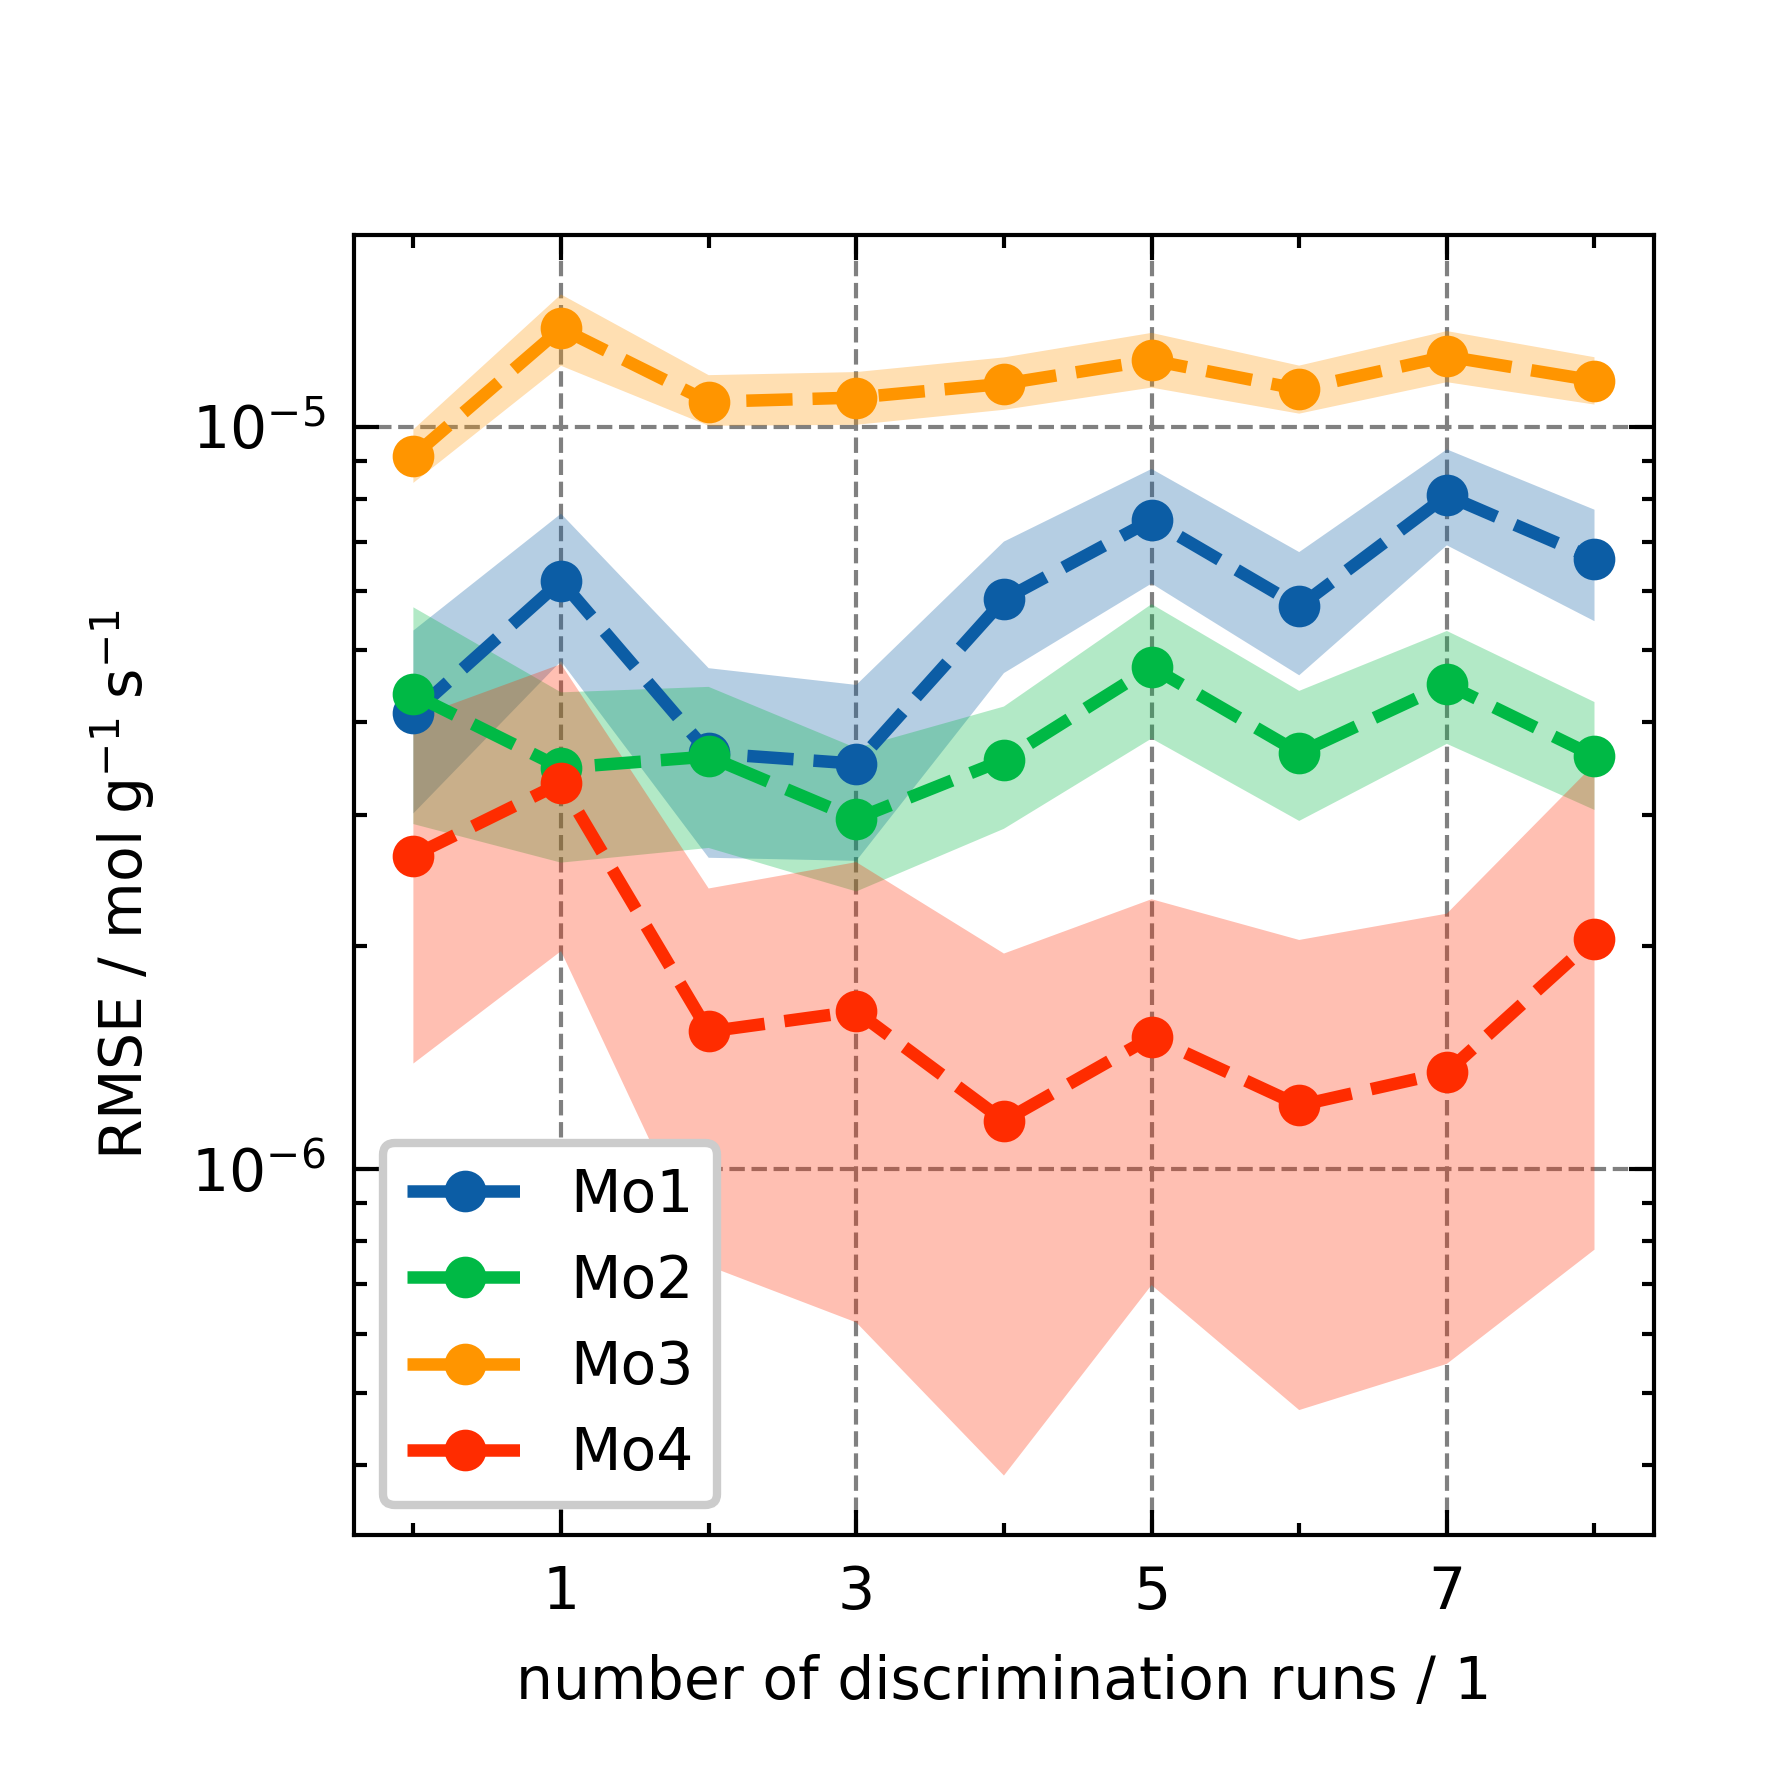

In [15]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of discrimination runs / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    left_h=1.5 * ICIW_Plots.cm2inch,
    xticks=[1, 3, 5, 7, 9],
)
ax.xaxis.set_minor_locator(plt.MultipleLocator(1))

def summarize_rmse(model_name):
    rmse_stack = jnp.stack([seed_data["RMSEs"][model_name] for seed_data in ov], axis=0)
    idxs = jnp.arange(0, rmse_stack.shape[1])
    mean_line = rmse_stack.mean(axis=(0, 2))
    pooled_draws = np.array(rmse_stack).transpose(1, 0, 2).reshape(rmse_stack.shape[1], -1)
    hdi = az.hdi(pooled_draws, 0.95, dim=1)
    return idxs, mean_line, hdi[:, 0], hdi[:, 1]

idxs, rmse1_mean, rmse1_low, rmse1_high = summarize_rmse("Mo1")
_, rmse2_mean, rmse2_low, rmse2_high = summarize_rmse("Mo2")
_, rmse3_mean, rmse3_low, rmse3_high = summarize_rmse("Mo3")
_, rmse4_mean, rmse4_low, rmse4_high = summarize_rmse("Mo4")

ax.plot(idxs, rmse1_mean, "o--", label="Mo1")
ax.fill_between(
    idxs,
    rmse1_low,
    rmse1_high,
    alpha=0.3,
)
ax.plot(idxs, rmse2_mean, "o--", label="Mo2")
ax.fill_between(
    idxs,
    rmse2_low,
    rmse2_high,
    alpha=0.3,
)
ax.plot(idxs, rmse3_mean, "o--", label="Mo3")
ax.fill_between(
    idxs,
    rmse3_low,
    rmse3_high,
    alpha=0.3,
)

ax.plot(idxs, rmse4_mean, "o--", label="Mo4")
ax.fill_between(
    idxs,
    rmse4_low,
    rmse4_high,
    alpha=0.3,
)

ax.legend()

plt.savefig("figures/rev/Deact_RMSE.png")
plt.savefig("figures/rev/Deact_RMSE.pdf")
plt.savefig("figures/rev/Deact_RMSE.svg")

In [26]:
ov[0]["idatas"]["Mo1"][-1]["posterior"]

<xarray.DataTree 'posterior'>
Group: /posterior
    Dimensions:         (chain: 8, draw: 4000, Ea_deact_dim_0: 1, Ea_k_dim_0: 1,
                         k0_dim_0: 1, k_deact_dim_0: 1, n_deact_dim_0: 1,
                         r_lat_dim_0: 20, r_lat_dim_1: 10, r_lat_dim_2: 1)
    Coordinates:
      * chain           (chain) int64 64B 0 1 2 3 4 5 6 7
      * draw            (draw) int64 32kB 0 1 2 3 4 5 ... 3995 3996 3997 3998 3999
      * Ea_deact_dim_0  (Ea_deact_dim_0) int64 8B 0
      * Ea_k_dim_0      (Ea_k_dim_0) int64 8B 0
      * k0_dim_0        (k0_dim_0) int64 8B 0
      * k_deact_dim_0   (k_deact_dim_0) int64 8B 0
      * n_deact_dim_0   (n_deact_dim_0) int64 8B 0
      * r_lat_dim_0     (r_lat_dim_0) int64 160B 0 1 2 3 4 5 6 ... 14 15 16 17 18 19
      * r_lat_dim_1     (r_lat_dim_1) int64 80B 0 1 2 3 4 5 6 7 8 9
      * r_lat_dim_2     (r_lat_dim_2) int64 8B 0
    Data variables:
        Ea_deact        (chain, draw, Ea_deact_dim_0) float32 128kB ...
        Ea_k            (chain, draw, Ea_k_dim_0) float32 128kB ...
        k0              (chain, draw, k0_dim_0) float32 128kB ...
        k_deact         (chain, draw, k_deact_dim_0) float32 128kB ...
        n_deact         (chain, draw, n_deact_dim_0) float32 128kB ...
        r_lat           (chain, draw, r_lat_dim_0, r_lat_dim_1, r_lat_dim_2) float32 26MB ...
        sigma_r         (chain, draw) float32 128kB ...
        t_Ea_deact      (chain, draw) float32 128kB ...
        t_Ea_k          (chain, draw) float32 128kB ...
        t_k0            (chain, draw) float32 128kB ...
        t_k_deact       (chain, draw) float32 128kB ...
        t_n_deact       (chain, draw) float32 128kB ...
    Attributes:
        created_at:                 2026-06-15T11:55:02.713475+00:00
        arviz_version:              0.22.0
        inference_library:          numpyro
        inference_library_version:  0.19.0

In [ ]:
import pandas as pd

pd.set_option("display.float_format", lambda x: "%.2e" % x)

summary_dir = Path("data/summaries/rev")
summary_dir.mkdir(parents=True, exist_ok=True)

var_names = [
    "k0",
    "Ea_k",
    "k_deact",
    "Ea_deact",
    "n_deact",
    "dH_h2",
    "A_mix",
    "dH_mix",
]


def collect_param_samples_last_iteration_by_model(model_name, key, group="posterior"):
    per_seed = []
    for ov_dict in ov:
        seed = ov_dict["seed"]
        idata = ov_dict["idatas"][model_name][-1]
        if idata is None:
            continue
        samples = idata[group][key].stack(sample=("chain", "draw")).values.squeeze()
        per_seed.append(
            xarray.DataArray(
                samples,
                dims=("sample",),
                coords={"sample": np.arange(samples.size)},
            ).expand_dims(seed=[seed])
        )
    if not per_seed:
        raise ValueError(f"No valid posterior samples found for {model_name}")
    return xarray.concat(per_seed, dim="seed")


for model_name in ["Mo1", "Mo2", "Mo3", "Mo4"]:
    print("=" * 40)
    print(f"Results for {model_name} at last DOE iteration")
    print("-" * 40)

    ds = xarray.Dataset()

    for param in var_names:
        samples = collect_param_samples_last_iteration_by_model(model_name, param)
        samples = samples.stack(flat=("seed", "sample")).values
        ds[param] = (("flat",), samples)
        print(samples.shape)

    summary = az.summary(
        ds,
        sample_dims=["flat"],
        var_names=var_names,
        round_to=14,
        fmt="wide",
        kind="stats",
        ci_kind="hdi",
        ci_prob=0.95,
    )
    # summary.to_csv(summary_dir / f"{model_name}_parameter_summary_last_iteration.csv")
    display(summary)

Results for Mo1 at last DOE iteration
----------------------------------------
(160000,)
(160000,)


KeyError: 'Could not find node at A_oh'